# 3. Cross-validation and replication of niches

This vignette evaluates GRASS-MIL by nested cross-validation (one image per
outer fold), analyses the niches of a fold model on the tiles it never saw, and
asks which niches recur across the fold models. It reuses the encoder pretrained
in vignette 2.

With three images, the folds are small: the numbers illustrate the procedure,
not the performance of the method.

In [1]:
import json
import pathlib
import subprocess

import pandas as pd
from IPython.display import Image, display

WORK = pathlib.Path("vignette_work").resolve()
DATA = WORK / "data"
COHORT = json.loads((WORK / "cohort.json").read_text())  # written by vignette 1

# Fine-tuning on a handful of tiles: a stronger probe penalty (the default C=1
# suits tens of thousands of ego-graphs) and more optimizer steps per epoch.
SMALL_DATA = ["finetune.probe.C=0.01", "finetune.hyperbatch_size=4"]


def run(command, *overrides):
    """Run a grass-mil command; show the end of its log if it fails.

    Commands that read the cohort (train, nested-cv, extract) get its settings;
    the analysis commands read a cell cache instead.
    """
    cohort = (
        COHORT["overrides"]
        if command in ("grass-mil-train", "grass-mil-nested-cv", "grass-mil-extract")
        else []
    )
    result = subprocess.run([command, *cohort, *overrides], capture_output=True, text=True)
    if result.returncode:
        print(result.stderr[-4000:])
        raise RuntimeError(f"{command} failed")


ENCODER = WORK / "pretrain" / "checkpoints" / "last.ckpt"

## Nested cross-validation

For every outer fold, the other two images are split into inner folds (here
`inner_k=2`, one image each); every inner run reports its best epoch, and the
model is refitted on both images for the median of those epochs and scored on
the held-out image.

In [2]:
run(
    "grass-mil-nested-cv",
    f"model.init_from_ckpt={ENCODER}",
    *SMALL_DATA,
    f"nested_cv.folds_file={DATA / 'folds.json'}",
    "nested_cv.inner_k=2",
    "trainer.max_epochs=20",
    "trainer.min_epochs=5",
    f"hydra.run.dir={WORK / 'nested_cv'}",
)
CV = WORK / "nested_cv"
summary = json.loads((CV / "nested_cv_summary.json").read_text())
print(f"AUROC per held-out image: {[round(v, 3) for v in summary['fold_values']]}")
print(
    f"mean ± s.d.: {summary['mean']:.3f} ± {summary['sd']:.3f}; pooled: {summary['pooled']['auroc']:.3f}"
)
pd.read_csv(CV / "oof_predictions.csv").round(3).head()

AUROC per held-out image: [0.917, 0.914, 0.891]
mean ± s.d.: 0.907 ± 0.014; pooled: 0.700


,outer,unit_id,prob_0,prob_1,pred,label,region_id,sample_id,patient_id
0,0,point16_tile000,0.009,0.991,1,1,point16,point16,point16
1,0,point16_tile001,0.004,0.996,1,1,point16,point16,point16
2,0,point16_tile002,0.001,0.999,1,1,point16,point16,point16
3,0,point16_tile003,0.048,0.952,1,1,point16,point16,point16
4,0,point16_tile004,0.006,0.994,1,1,point16,point16,point16


## Per-cell outputs of every fold model

Each fold model scores every tile; the cache records which tiles it held out.

In [3]:
run(
    "grass-mil-extract",
    f"extract.nested_cv_summary={CV / 'nested_cv_summary.json'}",
    f"extract.output_dir={WORK / 'cv_cells'}",
    f"hydra.run.dir={WORK / 'cv_extract'}",
)
sorted(p.name for p in (WORK / "cv_cells").iterdir())

['fold0', 'fold1', 'fold2']

## Niches of one fold model, on its held-out tiles

By default `grass-mil-niches` analyses the units the model did not train on;
as in vignette 2, leaf selection suits the small number of cells. The margin
intervals resample patients; this fold holds out one image, a single patient, so
they are not defined (NaN).

,niche,share,association,margin,margin_lo,margin_hi,composition
0,Niche 1,0.048,0.980,2.012,NaN,NaN,"Tcell_CD4 29%, Tcell_CD8 29%, Imm_other 18%"
1,Niche 2,0.035,1.000,1.850,NaN,NaN,"Tcell_CD8 33%, Epithelial 25%, Tcell_CD4 14%"
2,Niche 3,0.051,1.000,1.813,NaN,NaN,"Tcell_CD8 50%, Tcell_CD4 33%, Endothelial 8%"
3,Niche 4,0.030,0.774,1.318,NaN,NaN,"Tcell_CD4 39%, Tcell_CD8 23%, Fibroblast 16%"
4,Niche 5,0.033,0.824,1.259,NaN,NaN,"Tcell_CD4 50%, Tcell_CD8 26%, Fibroblast 12%"
5,Niche 6,0.038,1.000,1.204,NaN,NaN,"Tcell_CD4 31%, Tcell_CD8 31%, Epithelial 21%"
6,Niche 7,0.039,0.925,0.567,NaN,NaN,"Tcell_CD8 35%, Tcell_CD4 22%, Fibroblast 18%"
7,Niche 8,0.044,1.000,0.314,NaN,NaN,"Tcell_CD8 29%, Imm_other 27%, Fibroblast 24%"
8,Niche 9,0.071,0.247,-1.313,NaN,NaN,"Fibroblast 48%, Tcell_CD4 21%, Imm_other 18%"
9,Niche 10,0.050,0.686,-1.992,NaN,NaN,"Epithelial 51%, Tcell_CD8 24%, Tcell_CD4 12%"


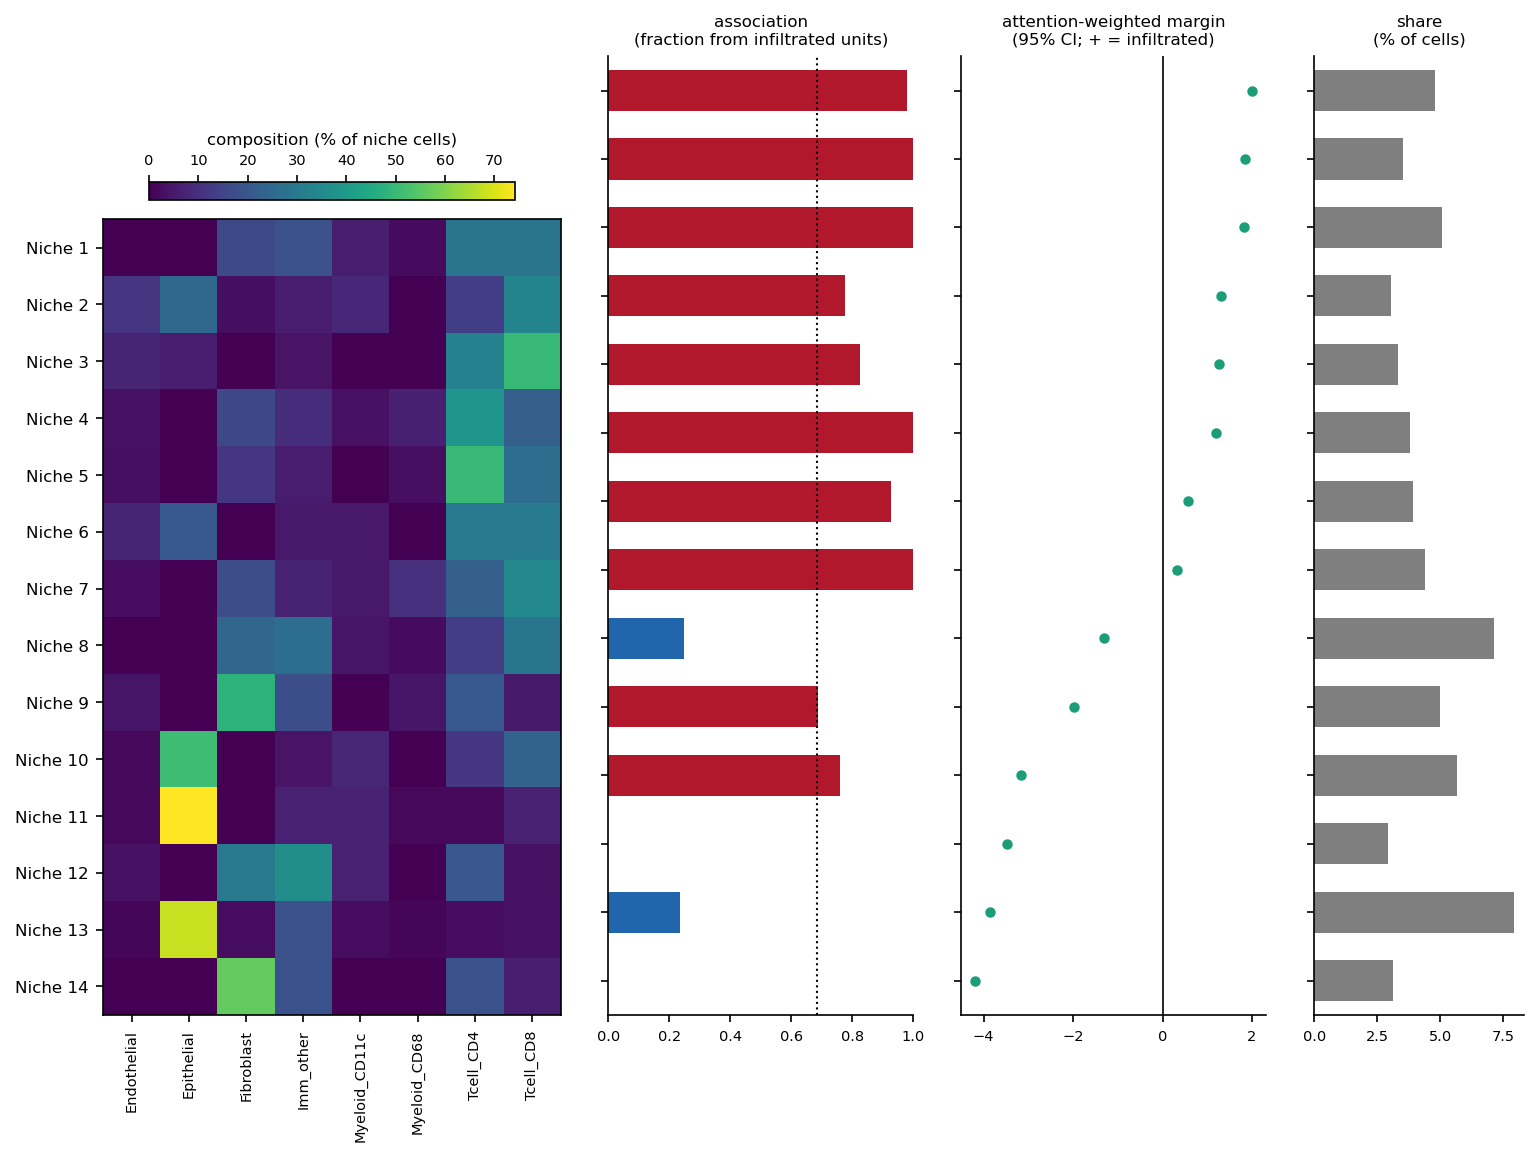

In [4]:
run(
    "grass-mil-niches",
    f"cells_dir={WORK / 'cv_cells' / 'fold0'}",
    "clustering.min_cluster_size=30",
    "clustering.selection=leaf",
    "positive_name=infiltrated",
    f"hydra.run.dir={WORK / 'cv_niches'}",
)
display(
    pd.read_csv(WORK / "cv_niches" / "niches.csv")[
        ["niche", "share", "association", "margin", "margin_lo", "margin_hi", "composition"]
    ].round(3)
)
display(Image(WORK / "cv_niches" / "figures" / "niche_panel.png"))

## Replication across fold models (optional)

Every fold model has its own embedding, so its niches are discovered on its own
held-out tiles. `grass-mil-metaclusters` matches niches of different models by
their cell-type composition; a metacluster found by at least `min_models`
models is replicated.

,metacluster,n_models,replicated,margin,association_vs_base,composition
0,M1,3,True,-0.015,-0.009,"Tcell_CD4 39%, Epithelial 14%, Myeloid_CD68 12%"
1,M2,3,True,0.397,0.154,"Tcell_CD4 30%, Epithelial 27%, Tcell_CD8 15%"
2,M3,3,True,-0.765,-0.249,"Epithelial 65%, Myeloid_CD11c 8%, Imm_other 7%"
3,M4,2,True,1.574,0.315,"Tcell_CD4 40%, Tcell_CD8 22%, Imm_other 21%"
4,M5,2,True,0.364,0.237,"Epithelial 40%, Tcell_CD8 18%, Endothelial 13%"
5,M6,2,True,1.421,0.303,"Tcell_CD8 45%, Tcell_CD4 31%, Imm_other 15%"
6,M7,2,True,1.176,0.225,"Tcell_CD4 51%, Tcell_CD8 19%, Imm_other 10%"
7,M8,2,True,0.669,0.186,"Tcell_CD4 33%, Tcell_CD8 24%, Imm_other 20%"
8,M9,2,True,0.153,0.147,"Epithelial 24%, Imm_other 18%, Myeloid_CD68 18%"
9,M10,2,True,-0.375,-0.108,"Fibroblast 45%, Tcell_CD4 18%, Myeloid_CD68 14%"


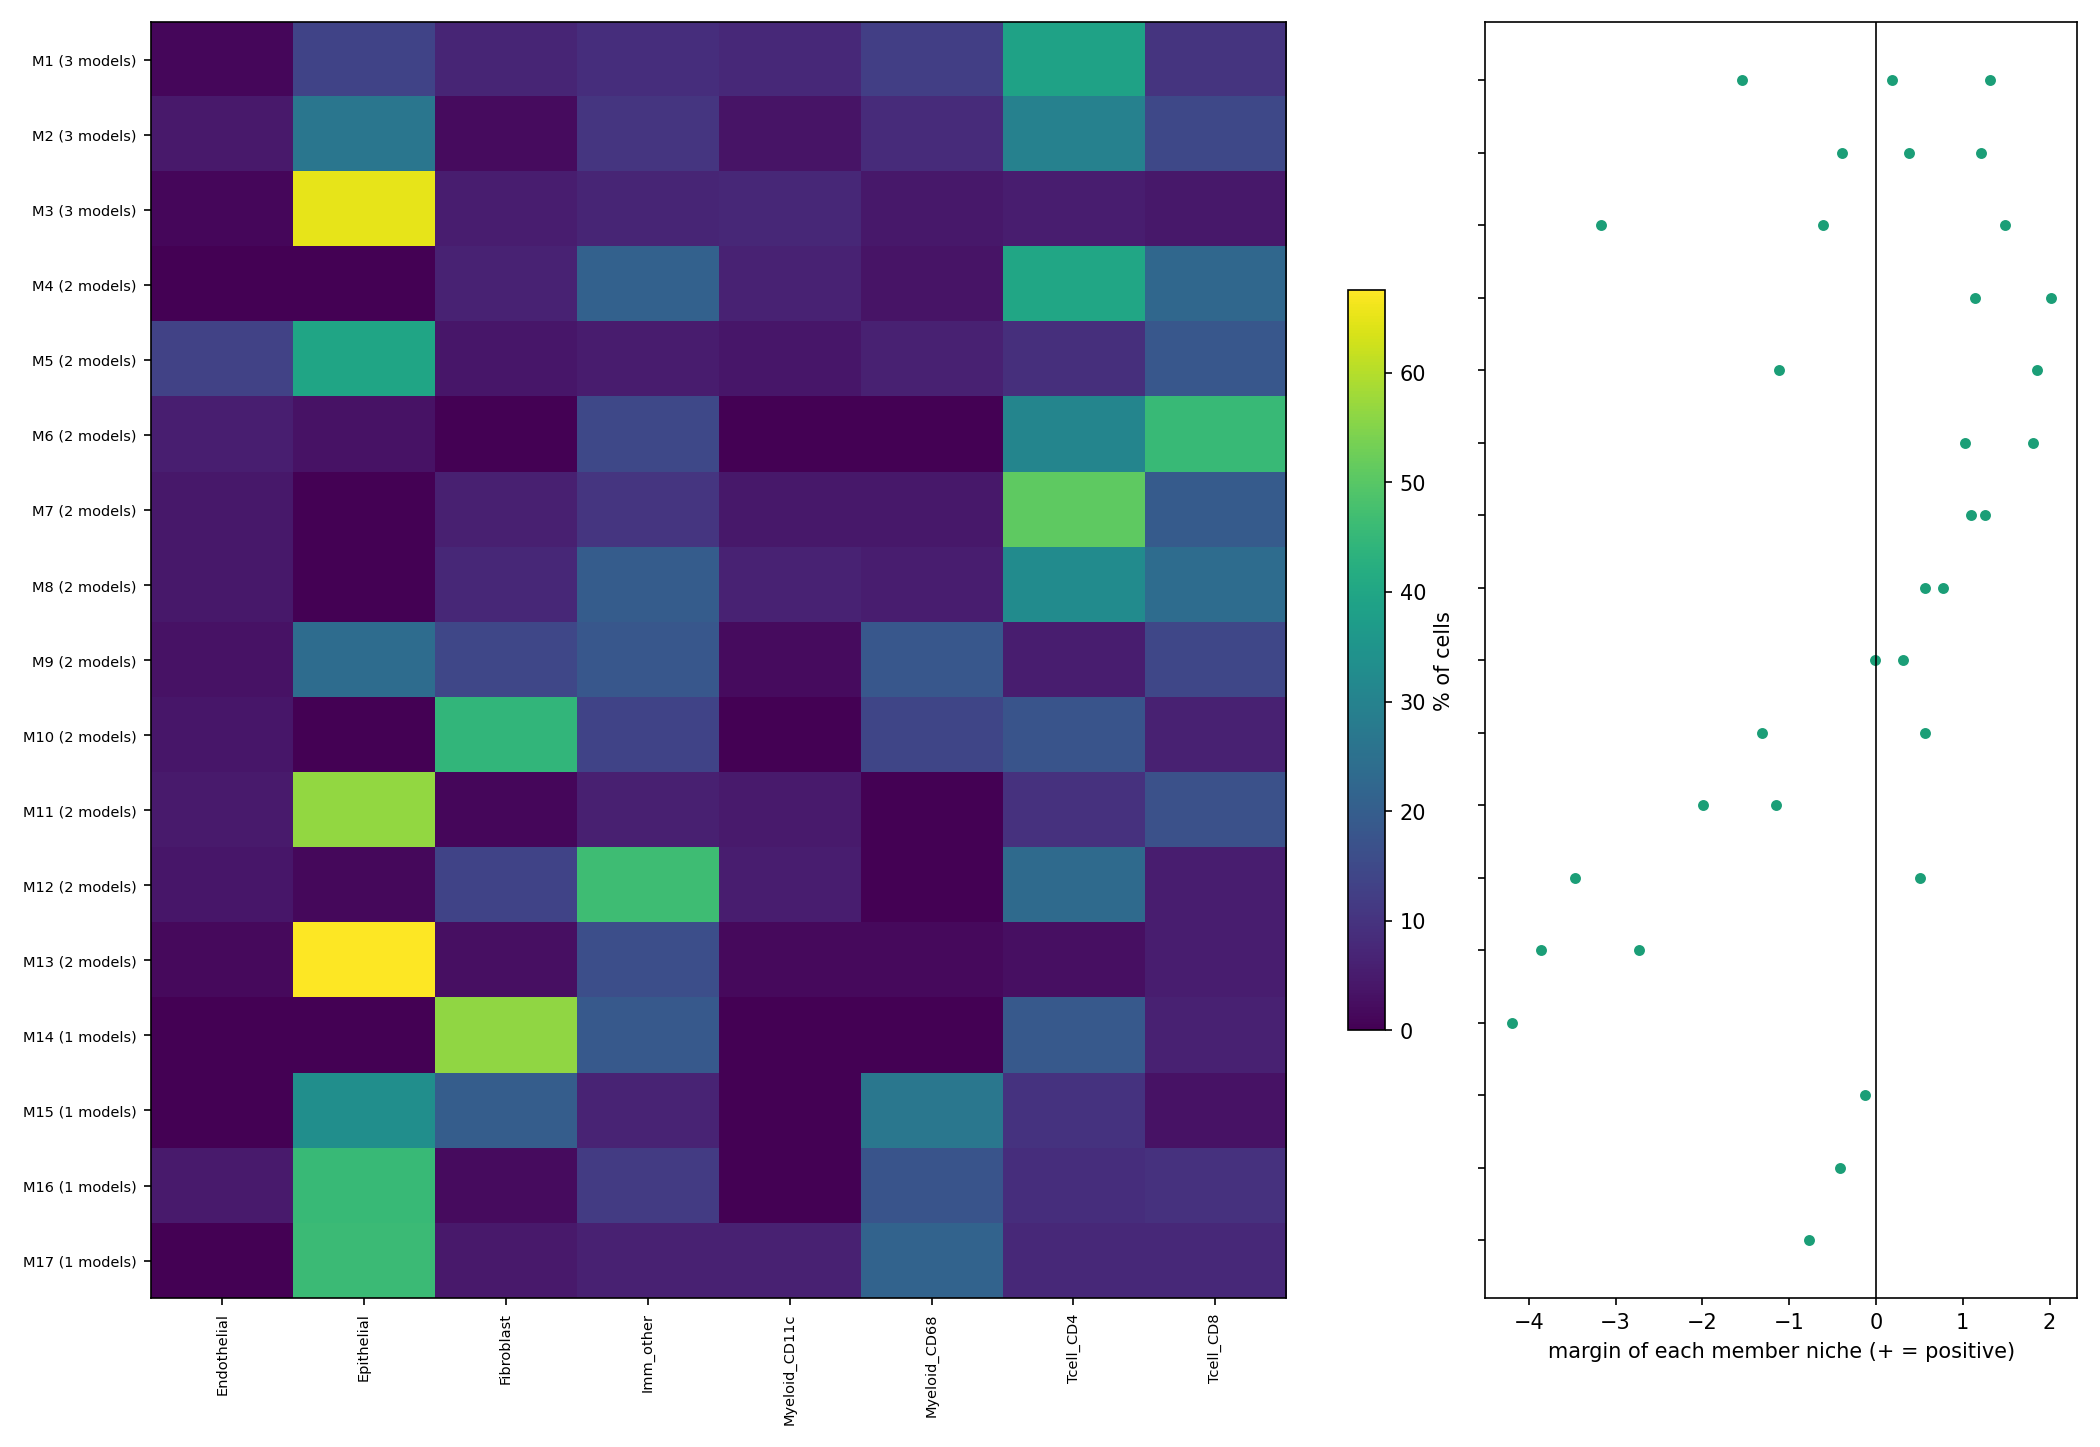

In [5]:
run(
    "grass-mil-metaclusters",
    f"cells_dir={WORK / 'cv_cells'}",
    "+clustering.min_cluster_size=30",
    "+clustering.selection=leaf",
    "match.min_models=2",
    "basis.k=6",
    f"hydra.run.dir={WORK / 'metaclusters'}",
)
META = WORK / "metaclusters"
display(
    pd.read_csv(META / "metaclusters.csv")[
        ["metacluster", "n_models", "replicated", "margin", "association_vs_base", "composition"]
    ].round(3)
)
display(Image(META / "metaclusters.png"))

## Model-free spatial statistics (optional)

The same cells, without a model: neighbourhood enrichment, cellular
neighbourhoods, and contacts and cross-L of epithelial cells with every other
type, compared between infiltrated and other tiles. With three images there
are too few patients to compare, so tiles are compared (`compare_by=unit`);
tiles of one image are not independent, so these p-values only illustrate the
output. On a cohort, patients are compared, each summarised by the mean over
its units.

In [6]:
run(
    "grass-mil-spatial-stats",
    f"cells_dir={WORK / 'cv_cells' / 'fold0'}",
    "reference=[Epithelial]",
    "compare_by=unit",
    "min_patients=3",
    f"hydra.run.dir={WORK / 'spatial_stats'}",
)
pd.read_csv(WORK / "spatial_stats" / "contacts_tests.csv").round(4).head(8)

,metric,n_pos,n_neg,mean_pos,mean_neg,auroc,p,diff,q
0,Epithelial->Epithelial,7,15,0.4995,0.8126,0.1905,0.0213,-0.3131,0.0945
1,Epithelial->Tcell_CD8,7,15,0.0967,0.0149,0.8000,0.0236,0.0818,0.0945
2,Epithelial->Tcell_CD4,7,15,0.1793,0.0355,0.7714,0.0462,0.1439,0.1232
3,Epithelial->Myeloid_CD68,7,15,0.0631,0.0430,0.3095,0.1590,0.0202,0.3180
4,Epithelial->Endothelial,7,15,0.0372,0.0177,0.6476,0.2826,0.0194,0.4522
5,Epithelial->Myeloid_CD11c,7,15,0.0527,0.0256,0.5810,0.5666,0.0271,0.7555
6,Epithelial->Fibroblast,7,15,0.0198,0.0077,0.4905,0.9674,0.0121,1.0000
7,Epithelial->Imm_other,7,15,0.0516,0.0430,0.5048,1.0000,0.0086,1.0000
